In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('Blues_r')

In [2]:
df = pd.read_csv('Dataset.csv', parse_dates=['Date'])
print('Shape:', df.shape)
df.head()

Shape: (50000, 14)


,Station_ID,Station_Name,Country_Code,Latitude,Longitude,Elevation_m,Date,Year,Month,Season,Average_Temperature_C,Rolling_3M_Avg_C,Month_Sin,Month_Cos
0,AE000041196,SHARJAH_INTER_AIRP,AE,25.333,55.517,34.0,2007-04-01,2007,4,Spring,29.10,29.1000,0.866,-0.500
1,AE000041196,SHARJAH_INTER_AIRP,AE,25.333,55.517,34.0,2007-05-01,2007,5,Spring,32.68,30.8900,0.500,-0.866
2,AE000041196,SHARJAH_INTER_AIRP,AE,25.333,55.517,34.0,2007-06-01,2007,6,Summer,33.68,31.8200,0.000,-1.000
3,AE000041196,SHARJAH_INTER_AIRP,AE,25.333,55.517,34.0,2007-07-01,2007,7,Summer,35.81,34.0567,-0.500,-0.866
4,AE000041196,SHARJAH_INTER_AIRP,AE,25.333,55.517,34.0,2007-08-01,2007,8,Summer,36.98,35.4900,-0.866,-0.500


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Station_ID             50000 non-null  str           
 1   Station_Name           50000 non-null  str           
 2   Country_Code           50000 non-null  str           
 3   Latitude               50000 non-null  float64       
 4   Longitude              50000 non-null  float64       
 5   Elevation_m            50000 non-null  float64       
 6   Date                   50000 non-null  datetime64[us]
 7   Year                   50000 non-null  int64         
 8   Month                  50000 non-null  int64         
 9   Season                 50000 non-null  str           
 10  Average_Temperature_C  50000 non-null  float64       
 11  Rolling_3M_Avg_C       50000 non-null  float64       
 12  Month_Sin              50000 non-null  float64       
 13  Month_Cos   

In [4]:
df.describe(include='number').T

,count,mean,std,min,25%,50%,75%,max
Latitude,50000.0,18.766212,27.316939,-63.400,1.5500,17.87190,42.2000,78.2500
Longitude,50000.0,17.517748,71.878464,-179.983,-18.6700,18.02655,51.5650,179.2170
Elevation_m,50000.0,320.126400,791.568114,0.000,10.7000,62.00000,307.0000,9999.0000
Year,50000.0,2016.804000,5.420337,2000.000,2012.0000,2017.00000,2021.0000,2026.0000
Month,50000.0,6.462020,3.444583,1.000,3.0000,6.00000,9.0000,12.0000
Average_Temperature_C,50000.0,19.784866,10.341707,-36.600,13.9200,23.90000,27.4500,40.6000
Rolling_3M_Avg_C,50000.0,19.757925,10.074638,-34.440,13.8933,23.71000,27.3767,39.9167
Month_Sin,50000.0,0.007053,0.705925,-1.000,-0.5000,0.00000,0.8660,1.0000
Month_Cos,50000.0,-0.006684,0.708213,-1.000,-0.8660,-0.00000,0.5000,1.0000


In [5]:
print('Total nulls:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Elevation sentinel (9999) rows:', (df.Elevation_m == 9999).sum())
print('Unique stations:', df.Station_ID.nunique())
print('Unique countries:', df.Country_Code.nunique())
print('Year range:', df.Year.min(), '-', df.Year.max())
print('Temperature range (°C):', df.Average_Temperature_C.min(), 'to', df.Average_Temperature_C.max())

Total nulls: 0
Duplicate rows: 0
Elevation sentinel (9999) rows: 200
Unique stations: 250
Unique countries: 196
Year range: 2000 - 2026
Temperature range (°C): -36.6 to 40.6


In [6]:
df_clean = df.copy()

# Sentinel -> NaN
df_clean['Elevation_m'] = df_clean['Elevation_m'].replace(9999, np.nan)

# Engineered grouping columns
df_clean['Decade'] = (df_clean['Year'] // 10) * 10
df_clean['Hemisphere'] = np.where(df_clean['Latitude'] >= 0, 'Northern', 'Southern')

# Sort for clean per-station time ordering
df_clean = df_clean.sort_values(['Station_ID', 'Date']).reset_index(drop=True)

print('Nulls after cleaning:\n', df_clean.isnull().sum()[df_clean.isnull().sum() > 0])
print('\nCleaned shape:', df_clean.shape)
df_clean.head()

Nulls after cleaning:
 Elevation_m    200
dtype: int64

Cleaned shape: (50000, 16)


,Station_ID,Station_Name,Country_Code,Latitude,Longitude,Elevation_m,Date,Year,Month,Season,Average_Temperature_C,Rolling_3M_Avg_C,Month_Sin,Month_Cos,Decade,Hemisphere
0,AE000041196,SHARJAH_INTER_AIRP,AE,25.333,55.517,34.0,2007-04-01,2007,4,Spring,29.10,29.1000,0.866,-0.500,2000,Northern
1,AE000041196,SHARJAH_INTER_AIRP,AE,25.333,55.517,34.0,2007-05-01,2007,5,Spring,32.68,30.8900,0.500,-0.866,2000,Northern
2,AE000041196,SHARJAH_INTER_AIRP,AE,25.333,55.517,34.0,2007-06-01,2007,6,Summer,33.68,31.8200,0.000,-1.000,2000,Northern
3,AE000041196,SHARJAH_INTER_AIRP,AE,25.333,55.517,34.0,2007-07-01,2007,7,Summer,35.81,34.0567,-0.500,-0.866,2000,Northern
4,AE000041196,SHARJAH_INTER_AIRP,AE,25.333,55.517,34.0,2007-08-01,2007,8,Summer,36.98,35.4900,-0.866,-0.500,2000,Northern


In [7]:
df_clean.to_csv('cleaned_station_temperature.csv', index=False)
print('Saved cleaned_station_temperature.csv:', df_clean.shape)

Saved cleaned_station_temperature.csv: (50000, 16)


In [8]:
print(df_clean['Season'].value_counts())
print()
print(df_clean.groupby('Hemisphere')['Average_Temperature_C'].describe()[['count', 'mean', 'std', 'min', 'max']])

Season
Summer    12659
Spring    12630
Winter    12535
Autumn    12176
Name: count, dtype: int64

              count       mean        std    min    max
Hemisphere                                             
Northern    38200.0  18.920912  10.922429 -36.60  40.60
Southern    11800.0  22.581734   7.532736 -15.65  33.02


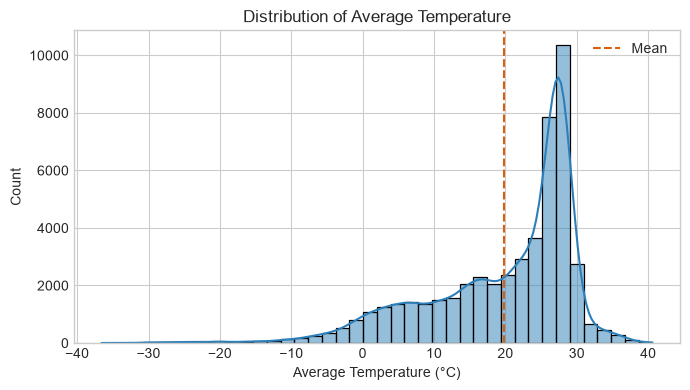

In [10]:
plt.figure(figsize=(7, 4))
sns.histplot(df_clean['Average_Temperature_C'], bins=40, kde=True, color='#2C7FB8')
plt.axvline(df_clean['Average_Temperature_C'].mean(), color='#D95F0E', linestyle='--', label='Mean')
plt.xlabel('Average Temperature (°C)')
plt.title('Distribution of Average Temperature')
plt.legend()
plt.tight_layout()
plt.savefig('fig1_temperature_distribution.png', dpi=150)
plt.show()

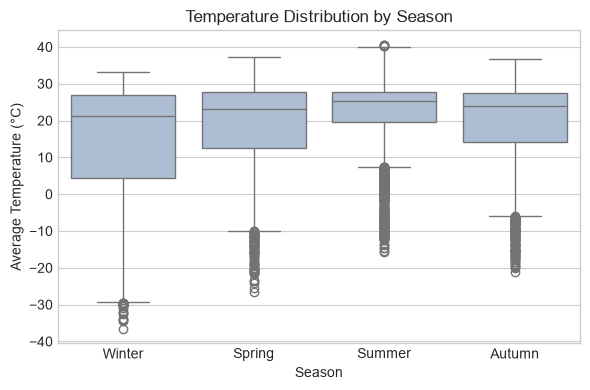

In [11]:
season_order = ['Winter', 'Spring', 'Summer', 'Autumn']
plt.figure(figsize=(6, 4))
sns.boxplot(data=df_clean, x='Season', y='Average_Temperature_C', order=season_order, color='#A6BDDB')
plt.title('Temperature Distribution by Season')
plt.ylabel('Average Temperature (°C)')
plt.tight_layout()
plt.savefig('fig2_temperature_by_season.png', dpi=150)
plt.show()

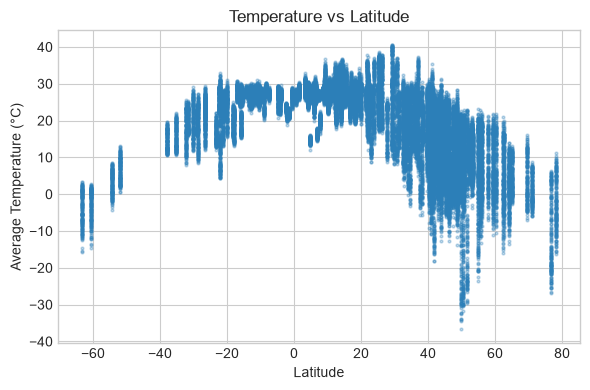

In [12]:
plt.figure(figsize=(6, 4))
plt.scatter(df_clean['Latitude'], df_clean['Average_Temperature_C'], s=4, alpha=0.3, color='#2C7FB8')
plt.xlabel('Latitude')
plt.ylabel('Average Temperature (°C)')
plt.title('Temperature vs Latitude')
plt.tight_layout()
plt.savefig('fig3_temp_vs_latitude.png', dpi=150)
plt.show()

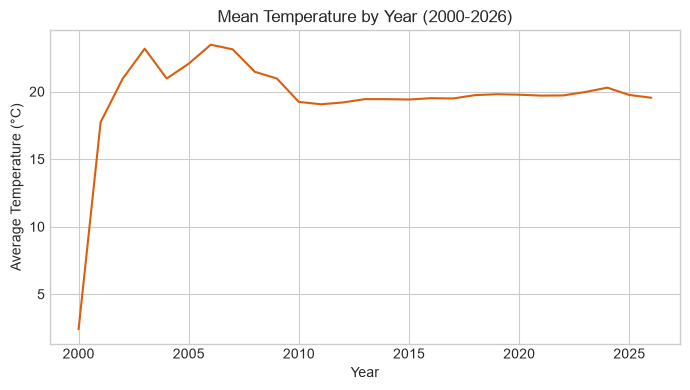

In [13]:
yearly = df_clean.groupby('Year')['Average_Temperature_C'].mean()
plt.figure(figsize=(7, 4))
yearly.plot(color='#D95F0E')
plt.ylabel('Average Temperature (°C)')
plt.title('Mean Temperature by Year (2000-2026)')
plt.tight_layout()
plt.savefig('fig4_yearly_trend.png', dpi=150)
plt.show()

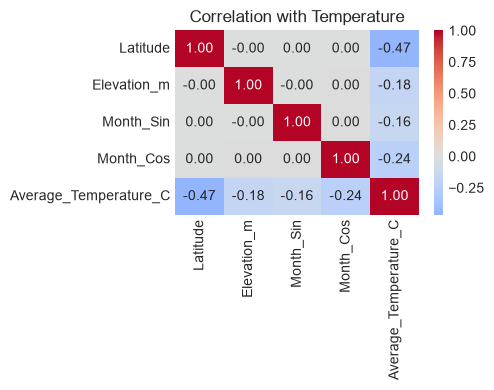

In [14]:
corr_cols = ['Latitude', 'Elevation_m', 'Month_Sin', 'Month_Cos', 'Average_Temperature_C']
corr = df_clean[corr_cols].corr()

plt.figure(figsize=(5, 4))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation with Temperature')
plt.tight_layout()
plt.savefig('fig5_correlation_heatmap.png', dpi=150)
plt.show()